<a href="https://colab.research.google.com/github/MelonG1t/copilot-repo/blob/main/ML1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Phase 0: Data import**

In [14]:
pip install -q kaggle

In [15]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("Hugo_kaggle_api")

print("Kaggle token loaded successfully.")


Kaggle token loaded successfully.


In [16]:
!kaggle datasets download -d zalando-research/fashionmnist -p /content/fashionmnist --unzip

Dataset URL: https://www.kaggle.com/datasets/zalando-research/fashionmnist
License(s): other
100% 68.8M/68.8M [00:02<00:00, 32.7MB/s]



In [24]:
import os

print(os.listdir("/content/fashionmnist"))

['t10k-images-idx3-ubyte', 'fashion-mnist_train.csv', 'train-images-idx3-ubyte', 'train-labels-idx1-ubyte', 't10k-labels-idx1-ubyte', 'fashion-mnist_test.csv']


In [18]:
from google.colab import drive
drive.mount("/content/drive")
!kaggle datasets download -d zalando-research/fashionmnist \
    -p /content/drive/MyDrive/fashionmnist --unzip

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset URL: https://www.kaggle.com/datasets/zalando-research/fashionmnist
License(s): other
100% 68.8M/68.8M [00:02<00:00, 32.2MB/s]



**Phase 1: check of the data set and familiarization**

In [25]:
from pathlib import Path

data_dir = Path("/content/fashionmnist")

for path in sorted(data_dir.iterdir()):
    print(path.name, "-", "directory" if path.is_dir() else f"{path.stat().st_size:,} bytes")

fashion-mnist_test.csv - 22,176,691 bytes
fashion-mnist_train.csv - 133,047,193 bytes
t10k-images-idx3-ubyte - 7,840,016 bytes
t10k-labels-idx1-ubyte - 10,008 bytes
train-images-idx3-ubyte - 47,040,016 bytes
train-labels-idx1-ubyte - 60,008 bytes


In [27]:
import pandas as pd

train_path = data_dir / "fashion-mnist_train.csv"
train_df = pd.read_csv(train_path)

print("Training rows and columns:", train_df.shape)
print("\nFirst five rows:")
display(train_df.head())

print("\nMissing values:", train_df.isnull().sum().sum())
print("Number of classes:", train_df.iloc[:, 0].nunique())
print("Pixel minimum:", train_df.iloc[:, 1:].min().min())
print("Pixel maximum:", train_df.iloc[:, 1:].max().max())


Training rows and columns: (60000, 785)

First five rows:


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Missing values: 0
Number of classes: 10
Pixel minimum: 0
Pixel maximum: 255


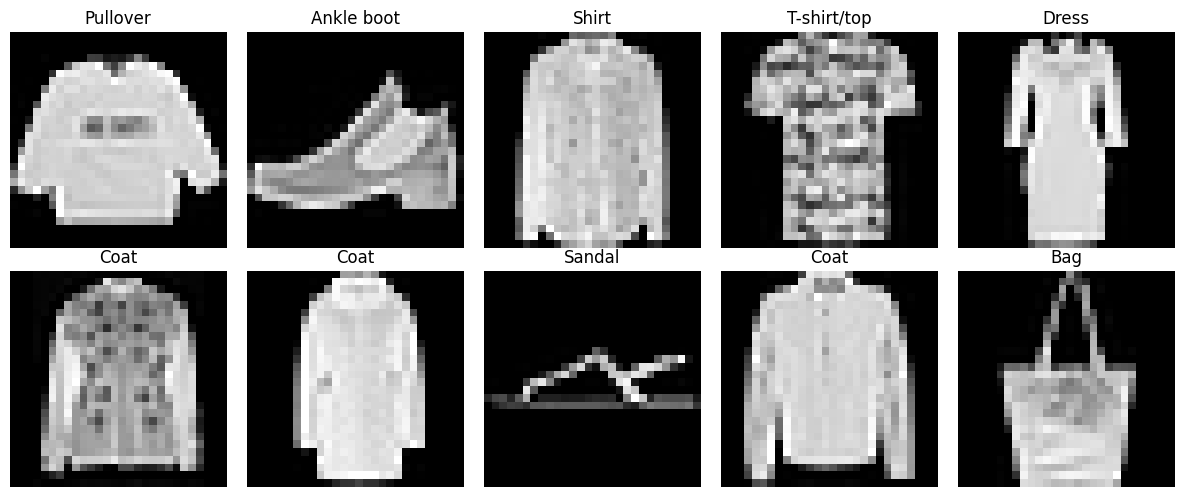

In [29]:
import matplotlib.pyplot as plt

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    label = int(train_df.iloc[i, 0])
    pixels = train_df.iloc[i, 1:].to_numpy()
    image = pixels.reshape(28, 28)

    ax.imshow(image, cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

Check that the classes are eavenly distributed into ten differnt calsses all with 6000 shapes

In [30]:
print(train_df.shape)
print(train_df.iloc[:, 0].value_counts().sort_index())

(60000, 785)
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


**Phase 2: Data engeneering**

import torch and split the data set and normalize the pixel values to [0,1] float32

In [32]:

import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader, random_split

SEED = 42
BATCH_SIZE = 128

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch version:", torch.__version__)
print("Random seed:", SEED)

assert train_df.shape == (60000, 785), (
    f"Unexpected CSV shape: {train_df.shape}"
)
assert not train_df.isnull().values.any(), "Missing values found!"

labels = train_df.iloc[:, 0].to_numpy(dtype=np.int64)
pixels = train_df.iloc[:, 1:].to_numpy(dtype=np.float32)

pixels = pixels / 255.0

images = pixels.reshape(-1, 1, 28, 28)

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Image dtype:", images.dtype)
print("Pixel range:", images.min(), "to", images.max())
print("Label dtype:", labels.dtype)

PyTorch version: 2.11.0+cpu
Random seed: 42
Images: (60000, 1, 28, 28)
Labels: (60000,)
Image dtype: float32
Pixel range: 0.0 to 1.0
Label dtype: int64


Class of data set

In [34]:

class FashionMNISTDataset(Dataset):
    def __init__(self, images, labels):
        # Store the prepared data as PyTorch tensors.
        self.images = torch.from_numpy(images)
        self.labels = torch.from_numpy(labels)

        # Check that every image has a corresponding label.
        assert len(self.images) == len(self.labels)

    def __len__(self):
        # Return the total number of examples.
        return len(self.labels)

    def __getitem__(self, index):
        # Return one image and its correct class label.
        return self.images[index], self.labels[index]


full_train_dataset = FashionMNISTDataset(images, labels)

print("Dataset size:", len(full_train_dataset))

sample_image, sample_label = full_train_dataset[0]

Dataset size: 60000


Split the data set into validation 10000 and training 50000

In [37]:

split_generator = torch.Generator().manual_seed(SEED)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [50000, 10000],
    generator=split_generator,
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))

Training examples: 50000
Validation examples: 10000


Data into batches loader

In [38]:

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 391
Validation batches: 79


Data set control

In [39]:

# Retrieve one batch.
batch_images, batch_labels = next(iter(train_loader))

print("Batch image shape:", batch_images.shape)
print("Batch label shape:", batch_labels.shape)
print("Image dtype:", batch_images.dtype)
print("Label dtype:", batch_labels.dtype)
print("Pixel range:", batch_images.min().item(),
      "to", batch_images.max().item())
print("Labels in this batch:",
      torch.unique(batch_labels).tolist())

# Automated checks.
assert batch_images.ndim == 4
assert batch_images.shape[1:] == (1, 28, 28)
assert batch_labels.ndim == 1
assert batch_images.shape[0] == batch_labels.shape[0]
assert batch_images.dtype == torch.float32
assert batch_labels.dtype == torch.long
assert batch_images.min() >= 0
assert batch_images.max() <= 1
assert batch_labels.min() >= 0
assert batch_labels.max() <= 9

print("All data pipeline checks passed!")


Batch image shape: torch.Size([128, 1, 28, 28])
Batch label shape: torch.Size([128])
Image dtype: torch.float32
Label dtype: torch.int64
Pixel range: 0.0 to 1.0
Labels in this batch: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
All data pipeline checks passed!


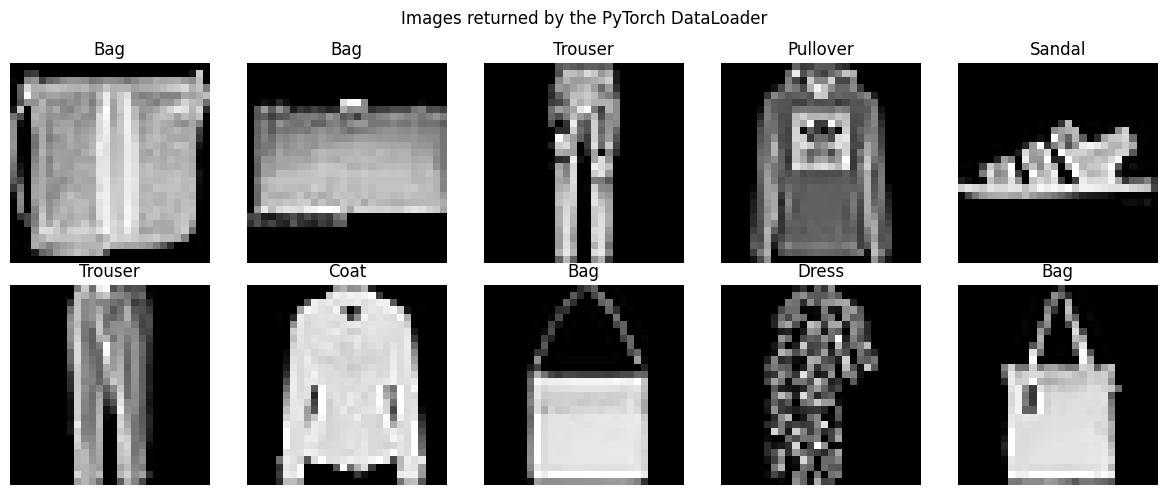

In [42]:

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = batch_images[i, 0].numpy()
    label = batch_labels[i].item()

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle("Images returned by the PyTorch DataLoader")
plt.tight_layout()
plt.show()


In [43]:

# random_split stores the original indices in each Subset.
train_indices = train_dataset.indices
val_indices = val_dataset.indices

train_class_counts = np.bincount(
    labels[train_indices], minlength=10
)
val_class_counts = np.bincount(
    labels[val_indices], minlength=10
)

distribution = pd.DataFrame({
    "Class": class_names,
    "Training": train_class_counts,
    "Validation": val_class_counts,
})

display(distribution)

assert len(set(train_indices).intersection(val_indices)) == 0
assert len(set(train_indices).union(val_indices)) == 60000

print("No overlap between training and validation indices.")

,Class,Training,Validation
0,T-shirt/top,4958,1042
1,Trouser,5039,961
2,Pullover,5016,984
3,Dress,4996,1004
4,Coat,4946,1054
5,Sandal,5008,992
6,Shirt,5032,968
7,Sneaker,5001,999
8,Bag,5008,992
9,Ankle boot,4996,1004


No overlap between training and validation indices.
